# Diagnostics D1 & D2 — first numbers (night 20→21 Oct 2026)

Reads only `results/*.json` and `data/diagnostics/*` — nothing is recomputed on models here.
Scripts: `src/diagnostics/d1_margin.py`, `d1_compare.py`, `d2_affix.py`. Seed 42, bootstrap 1000.

**Status of the Kazakh numbers: preliminary.** Kazakh paraphrases/negations (D1) and affix splits (D2)
are agent drafts marked `NEEDS_KZ_CHECK`; they will be recomputed after the owner's check.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.diagnostics.d1_margin import bootstrap_ci
R = ROOT / 'results'
load = lambda f: json.load(open(R / f, encoding='utf-8'))
d1 = {'ru': load('d1_margin_pilot_ru.json'), 'kz': load('d1_margin_prelim_kz.json')}
cmp_ = load('d1_compare_ru_kz.json')
d2 = load('d2_affix_isolation_prelim.json')
triples = {json.loads(l)['tid']: json.loads(l) for l in open(ROOT/'data/diagnostics/d1_triples.jsonl', encoding='utf-8')}

INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
COL = {'ru': '#2a78d6', 'kz': '#eb6834'}   # categorical slots 1-2 (validated)
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
pd.set_option('display.max_colwidth', 120)

C:\Users\Admin\Desktop\nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1021 01:20:36.276000 24056 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## D1 — Negation Margin

`margin = cos(s, paraphrase) − cos(s, negation)` on `intfloat/multilingual-e5-base` (`passage: `, normalized).
margin < 0 ⇒ the norm is closer to its **negation** than to its **paraphrase**.
Control: `min_paraphrase` — a one-span synonym edit at the same place as the negation edit
(«вправе» → «имеет право», «жол берілмейді» → «тыйым салынады»). It rules out "the paraphrase simply shares fewer words".

30 norms of the Labor Code, the **same norms** in Ru and Kz (adilet, ed. 15.09.2026).

In [2]:
rows = []
for lang, d in d1.items():
    s, c = d['summary'], d['control_min_paraphrase']['summary']
    rows.append({'lang': lang, 'n': s['n'],
                 'margin mean': round(s['mean'], 4), 'margin 95% CI': [round(x, 4) for x in s['mean_ci95']],
                 'share margin<0': f"{s['frac_negative']:.0%}",
                 'control mean': round(c['mean'], 4), 'control 95% CI': [round(x, 4) for x in c['mean_ci95']],
                 'share control<0': f"{c['frac_negative']:.0%}"})
pd.DataFrame(rows).set_index('lang')

,n,margin mean,margin 95% CI,share margin<0,control mean,control 95% CI,share control<0
lang,,,,,,,
ru,30,-0.0181,"[-0.0236, -0.0125]",90%,0.0179,"[0.0134, 0.0222]",7%
kz,30,-0.0134,"[-0.0202, -0.0063]",77%,0.0246,"[0.0197, 0.0298]",0%


### How far does each edit move the embedding?
Distance `1 − cos(s, ·)`, mean with 95% bootstrap CI. Negation moves the vector ~4–6× more than a synonym
edit (so e5 *does* register it), but **less than an ordinary rewording** — which is exactly what a user query is.

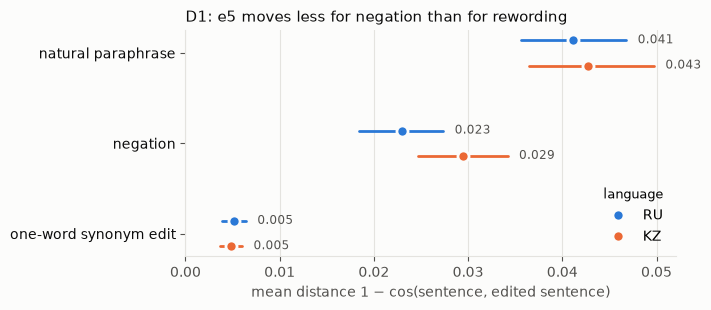

In [3]:
conds = [('cos_min_paraphrase', 'one-word synonym edit'), ('cos_negation', 'negation'), ('cos_paraphrase', 'natural paraphrase')]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for j, lang in enumerate(['ru', 'kz']):
    per = d1[lang]['per_triple']
    for i, (k, lab) in enumerate(conds):
        x = np.array([1 - p[k] for p in per]); m = x.mean(); lo, hi = bootstrap_ci(x)
        y = i + (0.14 if lang == 'ru' else -0.14)
        ax.plot([lo, hi], [y, y], color=COL[lang], lw=2, solid_capstyle='round')
        ax.plot(m, y, 'o', ms=8, color=COL[lang], mec='#fcfcfb', mew=2, label=lang.upper() if i == 0 else None)
        ax.text(hi + 0.0012, y, f'{m:.3f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(range(3)); ax.set_yticklabels([l for _, l in conds], color=INK)
ax.set_xlabel('mean distance 1 − cos(sentence, edited sentence)')
ax.set_xlim(0, None); ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right', title='language', title_fontsize=9)
ax.set_title('D1: e5 moves less for negation than for rewording', loc='left', color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(R / 'd1_distance_ladder.png', dpi=160); plt.show()

### Per-triple margins

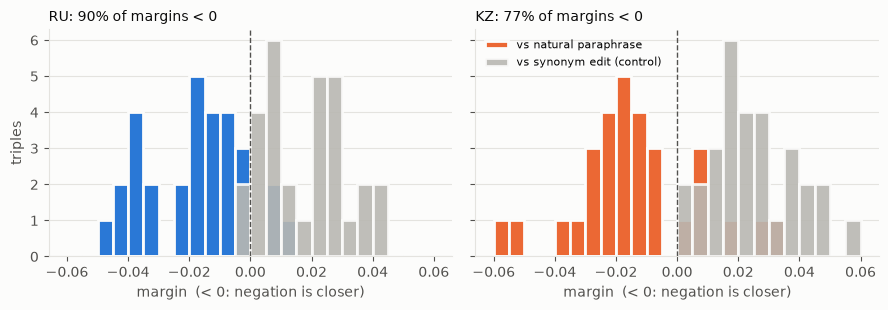

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, lang in zip(axes, ['ru', 'kz']):
    per = d1[lang]['per_triple']
    m = np.array([p['margin'] for p in per]); mm = np.array([p['margin_min'] for p in per])
    bins = np.linspace(-0.06, 0.06, 25)
    ax.hist(m, bins=bins, color=COL[lang], edgecolor='#fcfcfb', lw=2, label='vs natural paraphrase')
    ax.hist(mm, bins=bins, color='#b9b8b2', edgecolor='#fcfcfb', lw=2, alpha=0.9, label='vs synonym edit (control)')
    ax.axvline(0, color=INK2, lw=1, ls='--')
    ax.set_title(f"{lang.upper()}: {d1[lang]['summary']['frac_negative']:.0%} of margins < 0", loc='left', fontsize=10, color=INK)
    ax.set_xlabel('margin  (< 0: negation is closer)'); ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel('triples'); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(R / 'd1_margin_hist_ru_kz.png', dpi=160); plt.show()

### Ru vs Kz on the same norms (paired) and Kazakh negation mechanisms

In [5]:
print('paired delta (kz − ru):')
display(pd.DataFrame({k: {'mean Δ': round(v['mean_delta'], 4), '95% CI': [round(x, 4) for x in v['ci95']]}
                      for k, v in cmp_.items() if k in ('margin', 'margin_min')}).T)
mech = d1['kz']['by_neg_mechanism']
display(pd.DataFrame({k: {'n': v['margin']['n'], 'margin mean': round(v['margin']['mean'], 4),
                          '95% CI': [round(x, 4) for x in v['margin']['mean_ci95']],
                          'share <0': f"{v['margin']['frac_negative']:.0%}"} for k, v in mech.items()}).T)

paired delta (kz − ru):


,mean Δ,95% CI
margin,0.0047,"[-0.0019, 0.0109]"
margin_min,0.0067,"[0.0041, 0.0095]"


,n,margin mean,95% CI,share <0
affix,14,-0.0161,"[-0.0259, -0.0051]",79%
lexical,4,-0.0165,"[-0.046, 0.017]",75%
particle,12,-0.0091,"[-0.0158, -0.0023]",75%


### Examples (most negative margins)

In [6]:
ex = []
for lang in ['ru', 'kz']:
    for p in sorted(d1[lang]['per_triple'], key=lambda p: p['margin'])[:3]:
        t = triples[p['tid']]
        ex.append({'tid': p['tid'], 'cos(s,para)': round(p['cos_paraphrase'], 3), 'cos(s,neg)': round(p['cos_negation'], 3),
                   'sentence': t['sentence'], 'negation': t['negation'], 'paraphrase': t['paraphrase']})
pd.DataFrame(ex).set_index('tid')

,"cos(s,para)","cos(s,neg)",sentence,negation,paraphrase
tid,,,,,
ru002,0.938,0.984,"Условия соглашений, коллективных, трудовых договоров не могут быть изменены в одностороннем порядке, за исключением ...","Условия соглашений, коллективных, трудовых договоров могут быть изменены в одностороннем порядке, за исключением слу...","Одна сторона не может сама поменять условия трудового или коллективного договора либо соглашения, кроме случаев, ука..."
ru029,0.903,0.945,"Не допускается замена работников, участвующих в забастовке в соответствии с порядком, установленным законодательство...","Допускается замена работников, участвующих в забастовке в соответствии с порядком, установленным законодательством Р...","Работников, которые бастуют в законном порядке, нельзя заменять другими."
ru019,0.954,0.996,Продолжительность ежедневного (междусменного) отдыха работника между окончанием работы и ее началом на следующий ден...,Продолжительность ежедневного (междусменного) отдыха работника между окончанием работы и ее началом на следующий ден...,Между концом работы и её началом на следующий день у работника должно быть как минимум двенадцать часов отдыха.
kz027,0.897,0.955,Тараптардың ешқайсысы татуластыру рәсімдеріне қатысудан жалтаруға құқылы емес.,Тараптардың әрқайсысы татуластыру рәсімдеріне қатысудан жалтаруға құқылы.,Әр тарап татуластыру рәсімдеріне қатысуға міндетті.
kz019,0.936,0.987,Жұмыскердің жұмыстың аяқталуы мен оның келесі күні басталуы (жұмыс ауысымы) арасындағы күнделікті (ауысымаралық) тын...,Жұмыскердің жұмыстың аяқталуы мен оның келесі күні басталуы (жұмыс ауысымы) арасындағы күнделікті (ауысымаралық) тын...,Жұмыс аяқталғаннан бастап келесі күні қайта басталғанға дейін қызметкердің кемінде он екі сағат демалуы керек.
kz016,0.933,0.968,Жұмыс уақытының жиынтық есебі қолданылатын жұмысқа он сегіз жасқа толмаған жұмыскерлерді тартуға жол берілмейді.,Жұмыс уақытының жиынтық есебі қолданылатын жұмысқа он сегіз жасқа толмаған жұмыскерлерді тартуға жол беріледі.,Кәмелетке толмаған қызметкерлерді жұмыс уақыты жиынтық есеппен есептелетін жұмысқа тартуға болмайды.


## D2 — Affix Isolation Rate

171 distinct Kazakh negative verb forms found in the Kz Labor Code by the regex splitter
(`src/retrieval/morph_kz.py`), split as stem + **NEG** (-ма/-ме/-ба/-бе/-па/-пе) + ending.
Isolation = the XLM-R tokenizer puts a boundary **both** before and after the affix.
`xlm-roberta-base` and `multilingual-e5-base` have an identical vocabulary, so one number serves both.

In [7]:
t = d2['by_model']['xlm-roberta-base']; kz, ru = t['kz'], t['ru_control']
pd.DataFrame([
    {'measure': 'Kz: affix isolated (both boundaries)', 'value': f"{kz['isolation_rate']:.1%}", 'n': kz['n']},
    {'measure': 'Kz: affix isolated, weighted by corpus frequency', 'value': f"{kz['isolation_rate_freq_weighted']:.1%}", 'n': kz['corpus_tokens']},
    {'measure': 'Kz: at least one boundary', 'value': f"{kz['any_boundary_rate']:.1%}", 'n': kz['n']},
    {'measure': 'Ru control: separate «не» is its own token', 'value': f"{ru['particle_ne_own_token_rate']:.0%}", 'n': ru['particle_n']},
    {'measure': 'Ru control: fused prefix «не-» (неуплата) split off', 'value': f"{ru['fused_prefix_boundary_rate']:.0%}", 'n': ru['fused_n']},
]).set_index('measure')

,value,n
measure,,
Kz: affix isolated (both boundaries),21.1%,171
"Kz: affix isolated, weighted by corpus frequency",24.6%,581
Kz: at least one boundary,95.9%,171
Ru control: separate «не» is its own token,100%,12
Ru control: fused prefix «не-» (неуплата) split off,50%,30


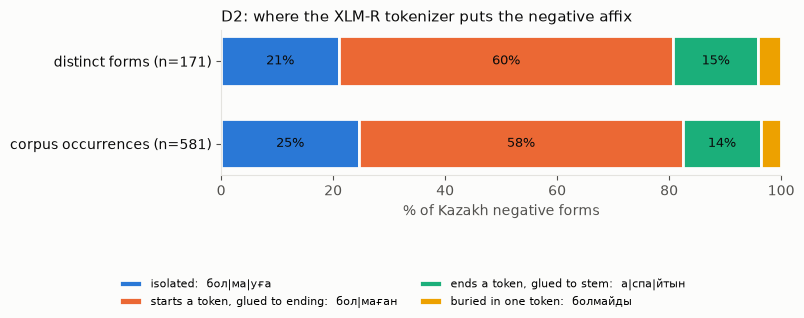

In [8]:
PAT = [('isolated', 'isolated:  бол|ма|уға', '#2a78d6'), ('starts_token', 'starts a token, glued to ending:  бол|маған', '#eb6834'),
       ('ends_token', 'ends a token, glued to stem:  а|спа|йтын', '#1baf7a'), ('buried', 'buried in one token:  болмайды', '#eda100')]
fig, ax = plt.subplots(figsize=(8, 3.3))
for y, (key, lab) in enumerate([('patterns', 'distinct forms (n=171)'), ('patterns_freq_weighted', 'corpus occurrences (n=581)')]):
    left = 0
    for k, name, c in PAT:
        w = kz[key][k] * 100
        ax.barh(y, w, left=left, color=c, edgecolor='#fcfcfb', lw=2, height=0.6, label=name if y == 0 else None)
        if w >= 6: ax.text(left + w / 2, y, f'{w:.0f}%', ha='center', va='center', fontsize=9, color=INK)
        left += w
ax.set_yticks([0, 1]); ax.set_yticklabels(['distinct forms (n=171)', 'corpus occurrences (n=581)'], color=INK)
ax.set_xlim(0, 100); ax.set_xlabel('% of Kazakh negative forms'); ax.invert_yaxis()
fig.legend(frameon=False, fontsize=8, ncol=2, loc='lower center')
ax.set_title('D2: where the XLM-R tokenizer puts the negative affix', loc='left', color=INK, fontsize=11)
fig.subplots_adjust(left=0.27, right=0.97, top=0.86, bottom=0.42); fig.savefig(R / 'd2_patterns.png', dpi=160); plt.show()

### 10 example tokenizations

In [9]:
forms = t['kz_forms']
pick = [f for f in forms if f['pattern'] == 'buried'][:3] + [f for f in forms if f['pattern'] == 'starts_token'][:3] \
     + [f for f in forms if f['pattern'] == 'ends_token'][:2] + [f for f in forms if f['pattern'] == 'isolated'][:2]
pd.DataFrame([{'form': f['form'], 'morphology': f['split'], 'XLM-R tokens': ' '.join(f['tokens']), 'pattern': f['pattern']} for f in pick]).set_index('form')

,morphology,XLM-R tokens,pattern
form,,,
болмайды,бол+ма+йды,▁болмайды,buried
жатпайды,жат+па+йды,▁жа тпай ды,buried
алмай,ал+ма+й,▁алмай,buried
болмаған,бол+ма+ған,▁бол маған,starts_token
берілмейді,беріл+ме+йді,▁бері л мейді,starts_token
сақталмайтын,сақтал+ма+йтын,▁сақта л майтын,starts_token
аспайтын,ас+па+йтын,▁а спа йтын,ends_token
аспауға,ас+па+уға,▁а спа уға,ends_token
қоспағанда,қос+па+ғанда,▁қос па ғанда,isolated


## Reading

* **D1 (Ru, final; Kz, preliminary):** e5 places a legal norm closer to its negation than to a paraphrase in 90% (Ru) / 77% (Kz)
  of cases. It is not blind to negation — a synonym edit moves the vector far less — but the negation signal is
  smaller than ordinary rewording, so a differently-worded query will sit closer to the wrong-polarity article.
  No Ru/Kz difference detected on the same norms.
* **D2 (preliminary):** the Kazakh negative affix is isolated by the tokenizer in ~21% of forms (threshold for
  refuting D2: ≥70%). Mostly it is glued to the tense ending (`маған`, `мейді`), sometimes to the stem (`спа`), and
  in frequent forms like `болмайды` it disappears inside one token. Russian fused «не-» is split off in only 50%.
* **Caveats:** n = 30 norms per language; Kazakh drafts unchecked; single model (e5-base).